In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

# Localizar la carpeta data.
possible_paths = [Path("data"), Path("../data")]

DATA_DIR = next(
    path for path in possible_paths
    if (path / "train.csv").exists()
)

# Cargar los archivos.
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(
    DATA_DIR / "sample_submission.csv"
)

# Dimensiones de los conjuntos.
print("Train:", train.shape)
print("Test:", test.shape)
print("Sample submission:", sample_submission.shape)

# Comprobar el objetivo.
print("\nValores ausentes en SalePrice:")
print(train["SalePrice"].isna().sum())

# Comprobar identificadores.
print("\nIDs duplicados en train:")
print(train["Id"].duplicated().sum())

print("\nIDs duplicados en test:")
print(test["Id"].duplicated().sum())

# Comprobar que train y test contienen las mismas
# características, excluyendo el objetivo.
train_features = set(train.columns) - {"SalePrice"}
test_features = set(test.columns)

print("\nColumnas que faltan en test:")
print(sorted(train_features - test_features))

print("\nColumnas adicionales en test:")
print(sorted(test_features - train_features))

# Primer vistazo a los valores ausentes.
missing = train.isna().sum()
missing = missing[missing > 0].sort_values(
    ascending=False
)

print("\nColumnas con valores ausentes:")
display(missing.to_frame(name="missing_count"))

Train: (1460, 81)
Test: (1459, 80)
Sample submission: (1459, 2)

Valores ausentes en SalePrice:
0

IDs duplicados en train:
0

IDs duplicados en test:
0

Columnas que faltan en test:
[]

Columnas adicionales en test:
[]

Columnas con valores ausentes:


,missing_count
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


In [3]:
def missing_report(df, name):
    report = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2)
    })

    report = report[report["missing_count"] > 0]
    report = report.sort_values(
        "missing_pct",
        ascending=False
    )

    print(f"\nValores ausentes en {name}:")
    display(report)


missing_report(train, "train")
missing_report(test, "test")


Valores ausentes en train:


,missing_count,missing_pct
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55



Valores ausentes en test:


,missing_count,missing_pct
PoolQC,1456,99.79
MiscFeature,1408,96.50
Alley,1352,92.67
Fence,1169,80.12
MasVnrType,894,61.27
FireplaceQu,730,50.03
LotFrontage,227,15.56
GarageQual,78,5.35
GarageCond,78,5.35
GarageYrBlt,78,5.35


In [4]:
# 1. Investigar los valores ausentes relacionados con el garaje.

garage_cols = [
    "GarageType",
    "GarageYrBlt",
    "GarageFinish",
    "GarageCars",
    "GarageArea",
    "GarageQual",
    "GarageCond",
]

display(
    train.loc[
        train["GarageType"].isna(),
        garage_cols
    ].head(10)
)

print(
    "Casas sin GarageType pero con GarageCars > 0:",
    (
        train.loc[train["GarageType"].isna(), "GarageCars"] > 0
    ).sum()
)

print(
    "Casas sin GarageType pero con GarageArea > 0:",
    (
        train.loc[train["GarageType"].isna(), "GarageArea"] > 0
    ).sum()
)


# 2. Investigar el revestimiento de mampostería.

mas_vnr_missing = train[
    ["MasVnrType", "MasVnrArea"]
].isna().any(axis=1)

display(
    train.loc[
        mas_vnr_missing,
        ["Id", "MasVnrType", "MasVnrArea", "SalePrice"]
    ]
)


# 3. Examinar los valores ausentes de LotFrontage.

display(
    train.loc[
        train["LotFrontage"].isna(),
        ["Id", "Neighborhood", "LotArea", "LotFrontage"]
    ].head(10)
)


# 4. Examinar el registro sin información eléctrica.

display(
    train.loc[
        train["Electrical"].isna(),
        ["Id", "Electrical", "CentralAir", "Heating", "SalePrice"]
    ]
)

,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond
39,NaN,NaN,NaN,0,0,NaN,NaN
48,NaN,NaN,NaN,0,0,NaN,NaN
78,NaN,NaN,NaN,0,0,NaN,NaN
88,NaN,NaN,NaN,0,0,NaN,NaN
89,NaN,NaN,NaN,0,0,NaN,NaN
99,NaN,NaN,NaN,0,0,NaN,NaN
108,NaN,NaN,NaN,0,0,NaN,NaN
125,NaN,NaN,NaN,0,0,NaN,NaN
127,NaN,NaN,NaN,0,0,NaN,NaN
140,NaN,NaN,NaN,0,0,NaN,NaN


Casas sin GarageType pero con GarageCars > 0: 0
Casas sin GarageType pero con GarageArea > 0: 0


,Id,MasVnrType,MasVnrArea,SalePrice
1,2,NaN,0.0,181500
3,4,NaN,0.0,140000
5,6,NaN,0.0,143000
8,9,NaN,0.0,129900
9,10,NaN,0.0,118000
...,...,...,...,...
1454,1455,NaN,0.0,185000
1455,1456,NaN,0.0,175000
1457,1458,NaN,0.0,266500
1458,1459,NaN,0.0,142125


,Id,Neighborhood,LotArea,LotFrontage
7,8,NWAmes,10382,NaN
12,13,Sawyer,12968,NaN
14,15,NAmes,10920,NaN
16,17,NAmes,11241,NaN
24,25,Sawyer,8246,NaN
31,32,Sawyer,8544,NaN
42,43,SawyerW,9180,NaN
43,44,CollgCr,9200,NaN
50,51,Gilbert,13869,NaN
64,65,CollgCr,9375,NaN


,Id,Electrical,CentralAir,Heating,SalePrice
1379,1380,NaN,Y,GasA,167500


In [5]:
# Crear máscaras para identificar los valores ausentes.
type_missing = train["MasVnrType"].isna()
area_missing = train["MasVnrArea"].isna()

# Comprobar cómo se relacionan ambas variables.
print(
    "MasVnrType ausente y MasVnrArea = 0:",
    (type_missing & train["MasVnrArea"].eq(0)).sum()
)

print(
    "MasVnrType ausente y MasVnrArea > 0:",
    (type_missing & train["MasVnrArea"].gt(0)).sum()
)

print(
    "Ambas variables ausentes:",
    (type_missing & area_missing).sum()
)

print(
    "MasVnrType presente y MasVnrArea ausente:",
    ((~type_missing) & area_missing).sum()
)

# Mostrar las filas donde falta el área.
display(
    train.loc[
        area_missing,
        ["Id", "MasVnrType", "MasVnrArea", "SalePrice"]
    ]
)

MasVnrType ausente y MasVnrArea = 0: 859
MasVnrType ausente y MasVnrArea > 0: 5
Ambas variables ausentes: 8
MasVnrType presente y MasVnrArea ausente: 0


,Id,MasVnrType,MasVnrArea,SalePrice
234,235,NaN,NaN,216500
529,530,NaN,NaN,200624
650,651,NaN,NaN,205950
936,937,NaN,NaN,184900
973,974,NaN,NaN,182000
977,978,NaN,NaN,199900
1243,1244,NaN,NaN,465000
1278,1279,NaN,NaN,237000


In [6]:
# Identificar viviendas con tipo ausente y área positiva.
mask = (
    train["MasVnrType"].isna()
    & train["MasVnrArea"].gt(0)
)

columns = [
    "Id",
    "MasVnrType",
    "MasVnrArea",
    "Neighborhood",
    "OverallQual",
    "YearBuilt",
    "SalePrice",
]

display(train.loc[mask, columns])

,Id,MasVnrType,MasVnrArea,Neighborhood,OverallQual,YearBuilt,SalePrice
624,625,NaN,288.0,NWAmes,6,1972,165150
773,774,NaN,1.0,NAmes,5,1958,114500
1230,1231,NaN,1.0,Sawyer,5,1977,190000
1300,1301,NaN,344.0,Gilbert,7,1999,225000
1334,1335,NaN,312.0,BrDale,5,1970,125000


In [7]:
# Viviendas en las que faltan tanto el tipo como el área.
both_missing = (
    train["MasVnrType"].isna()
    & train["MasVnrArea"].isna()
)

columns = [
    "Id",
    "Neighborhood",
    "OverallQual",
    "YearBuilt",
    "Exterior1st",
    "Exterior2nd",
    "MasVnrType",
    "MasVnrArea",
    "SalePrice",
]

display(train.loc[both_missing, columns])

,Id,Neighborhood,OverallQual,YearBuilt,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,SalePrice
234,235,Gilbert,6,2002,VinylSd,VinylSd,NaN,NaN,216500
529,530,Crawfor,6,1957,Wd Sdng,Stone,NaN,NaN,200624
650,651,Somerst,7,2007,CemntBd,CmentBd,NaN,NaN,205950
936,937,SawyerW,7,2003,VinylSd,VinylSd,NaN,NaN,184900
973,974,Somerst,7,2007,CemntBd,CmentBd,NaN,NaN,182000
977,978,Somerst,7,2006,VinylSd,VinylSd,NaN,NaN,199900
1243,1244,NridgHt,10,2006,VinylSd,VinylSd,NaN,NaN,465000
1278,1279,CollgCr,8,2002,VinylSd,VinylSd,NaN,NaN,237000


In [8]:
# 1. Resumen de tipos de datos.
print("=== Tipos de datos ===")
print(train.dtypes.value_counts())

# Ver el tipo, número de valores distintos y valores ausentes
# de cada columna.
dtype_report = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "unique_values": train.nunique(),
    "missing_values": train.isna().sum(),
})

display(dtype_report)


# 2. Comprobar filas duplicadas completas.
print("\n=== Filas duplicadas ===")
print("Train:", train.duplicated().sum())
print("Test:", test.duplicated().sum())


# 3. Comprobar identificadores compartidos.
shared_ids = set(train["Id"]) & set(test["Id"])

print("\n=== Identificadores ===")
print("IDs compartidos entre train y test:", len(shared_ids))


# 4. Comprobar la variable objetivo.
print("\n=== SalePrice ===")
print("Valores no positivos:", (train["SalePrice"] <= 0).sum())
print("Valores no finitos:", (~np.isfinite(train["SalePrice"])).sum())


# 5. Comparar valores ausentes en train y test.
missing_comparison = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "train_pct": (train.isna().mean() * 100).round(2),
    "test_missing": test.isna().sum(),
    "test_pct": (test.isna().mean() * 100).round(2),
}).fillna(0)

missing_comparison = missing_comparison.sort_values(
    ["train_missing", "test_missing"],
    ascending=False,
)

display(missing_comparison.head(25))


# 6. Comprobar que los tipos de las características coinciden.
train_features = train.drop(columns="SalePrice")

dtype_comparison = pd.DataFrame({
    "train_dtype": train_features.dtypes.astype(str),
    "test_dtype": test.dtypes.astype(str),
})

print("\n=== Diferencias de tipos entre train y test ===")
display(
    dtype_comparison[
        dtype_comparison["train_dtype"]
        != dtype_comparison["test_dtype"]
    ]
)

=== Tipos de datos ===
str        43
int64      35
float64     3
Name: count, dtype: int64


,dtype,unique_values,missing_values
Id,int64,1460,0
MSSubClass,int64,15,0
MSZoning,str,5,0
LotFrontage,float64,110,259
LotArea,int64,1073,0
...,...,...,...
MoSold,int64,12,0
YrSold,int64,5,0
SaleType,str,9,0
SaleCondition,str,6,0



=== Filas duplicadas ===
Train: 0
Test: 0

=== Identificadores ===
IDs compartidos entre train y test: 0

=== SalePrice ===
Valores no positivos: 0
Valores no finitos: 0


,train_missing,train_pct,test_missing,test_pct
PoolQC,1453,99.52,1456.0,99.79
MiscFeature,1406,96.30,1408.0,96.50
Alley,1369,93.77,1352.0,92.67
Fence,1179,80.75,1169.0,80.12
MasVnrType,872,59.73,894.0,61.27
FireplaceQu,690,47.26,730.0,50.03
LotFrontage,259,17.74,227.0,15.56
GarageCond,81,5.55,78.0,5.35
GarageFinish,81,5.55,78.0,5.35
GarageQual,81,5.55,78.0,5.35



=== Diferencias de tipos entre train y test ===


,train_dtype,test_dtype
BsmtFinSF1,int64,float64
BsmtFinSF2,int64,float64
BsmtUnfSF,int64,float64
TotalBsmtSF,int64,float64
BsmtFullBath,int64,float64
BsmtHalfBath,int64,float64
GarageCars,int64,float64
GarageArea,int64,float64


In [9]:
# 1. Resumen de las variables numéricas.
numeric_cols = train.select_dtypes(include=np.number).columns

numeric_summary = train[numeric_cols].describe().T

display(
    numeric_summary[
        ["min", "25%", "50%", "75%", "max"]
    ]
)


# 2. Buscar valores negativos.
negative_train = (
    train.select_dtypes(include=np.number) < 0
).sum()

negative_test = (
    test.select_dtypes(include=np.number) < 0
).sum()

print("Valores negativos en train:")
display(negative_train[negative_train > 0])

print("Valores negativos en test:")
display(negative_test[negative_test > 0])


# 3. Comprobar coherencia de los años.
year_checks = {
    "YearBuilt > YrSold":
        train["YearBuilt"] > train["YrSold"],

    "YearRemodAdd > YrSold":
        train["YearRemodAdd"] > train["YrSold"],

    "YearRemodAdd < YearBuilt":
        train["YearRemodAdd"] < train["YearBuilt"],

    "GarageYrBlt > YrSold":
        train["GarageYrBlt"] > train["YrSold"],
}

print("Comprobaciones de coherencia temporal:")

for name, condition in year_checks.items():
    print(f"{name}: {condition.sum()} casos")


# 4. Comprobar los meses de venta.
invalid_months = ~train["MoSold"].between(1, 12)

print(
    "Valores de MoSold fuera del rango 1-12:",
    invalid_months.sum()
)

,min,25%,50%,75%,max
Id,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,20.0,20.00,50.0,70.00,190.0
LotFrontage,21.0,59.00,69.0,80.00,313.0
LotArea,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1.0,5.00,6.0,7.00,10.0
OverallCond,1.0,5.00,5.0,6.00,9.0
YearBuilt,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,0.0,0.00,383.5,712.25,5644.0


Valores negativos en train:


Series([], dtype: int64)

Valores negativos en test:


Series([], dtype: int64)

Comprobaciones de coherencia temporal:
YearBuilt > YrSold: 0 casos
YearRemodAdd > YrSold: 1 casos
YearRemodAdd < YearBuilt: 0 casos
GarageYrBlt > YrSold: 0 casos
Valores de MoSold fuera del rango 1-12: 0


In [10]:
# Investigar viviendas reformadas después del año de venta.
temporal_issue = train.loc[
    train["YearRemodAdd"] > train["YrSold"],
    [
        "Id",
        "YearBuilt",
        "YearRemodAdd",
        "YrSold",
        "Neighborhood",
        "OverallQual",
        "SalePrice",
    ],
]

display(temporal_issue)

,Id,YearBuilt,YearRemodAdd,YrSold,Neighborhood,OverallQual,SalePrice
523,524,2007,2008,2007,Edwards,10,184750


In [11]:
# Revisar anomalías temporales en ambos conjuntos.
for name, df in [("train", train), ("test", test)]:

    mask = df["YearRemodAdd"] > df["YrSold"]

    print(f"\nAnomalías temporales en {name}: {mask.sum()}")

    display(
        df.loc[
            mask,
            ["Id", "YearBuilt", "YearRemodAdd", "YrSold"]
        ]
    )


Anomalías temporales en train: 1


,Id,YearBuilt,YearRemodAdd,YrSold
523,524,2007,2008,2007



Anomalías temporales en test: 2


,Id,YearBuilt,YearRemodAdd,YrSold
835,2296,2007,2008,2007
1089,2550,2008,2009,2007


# 2.1. Análisis de la variable objetivo


In [12]:
# Estadísticas descriptivas del precio de venta.
saleprice_stats = train["SalePrice"].describe()

display(saleprice_stats)

# Estadísticas adicionales.
print("Media:", train["SalePrice"].mean())
print("Mediana:", train["SalePrice"].median())
print("Desviación estándar:", train["SalePrice"].std())
print("Asimetría (skewness):", train["SalePrice"].skew())
print("Número de precios únicos:", train["SalePrice"].nunique())

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Media: 180921.19589041095
Mediana: 163000.0
Desviación estándar: 79442.50288288662
Asimetría (skewness): 1.8828757597682129
Número de precios únicos: 663


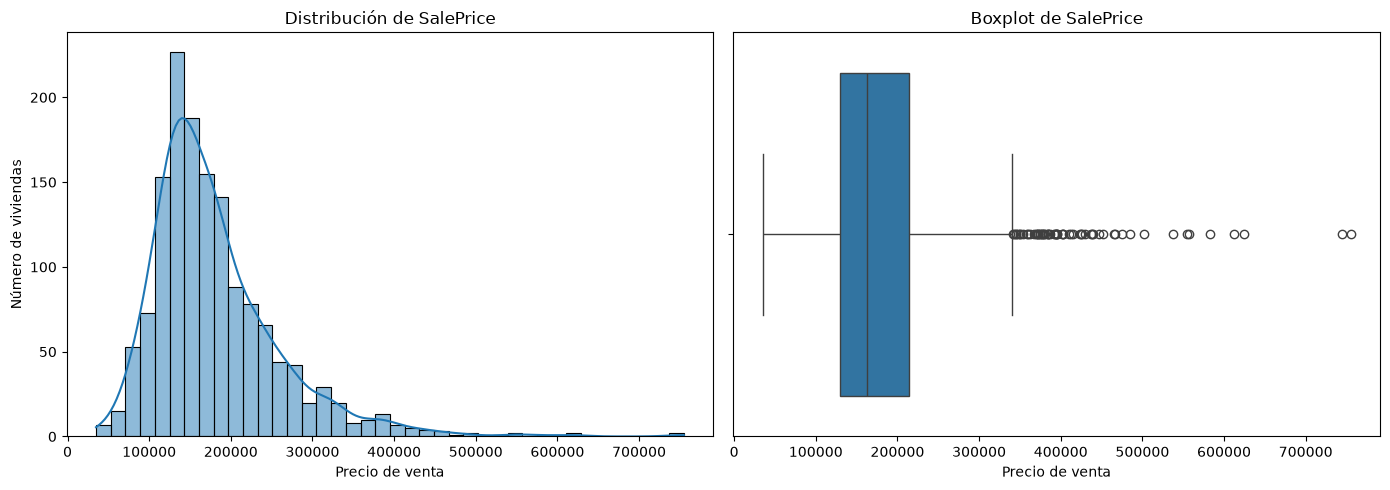

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma: distribución de los precios.
sns.histplot(
    data=train,
    x="SalePrice",
    bins=40,
    kde=True,
    ax=axes[0],
)

axes[0].set_title("Distribución de SalePrice")
axes[0].set_xlabel("Precio de venta")
axes[0].set_ylabel("Número de viviendas")

# Boxplot: dispersión y posibles valores atípicos.
sns.boxplot(
    data=train,
    x="SalePrice",
    ax=axes[1],
)

axes[1].set_title("Boxplot de SalePrice")
axes[1].set_xlabel("Precio de venta")

plt.tight_layout()
plt.show()

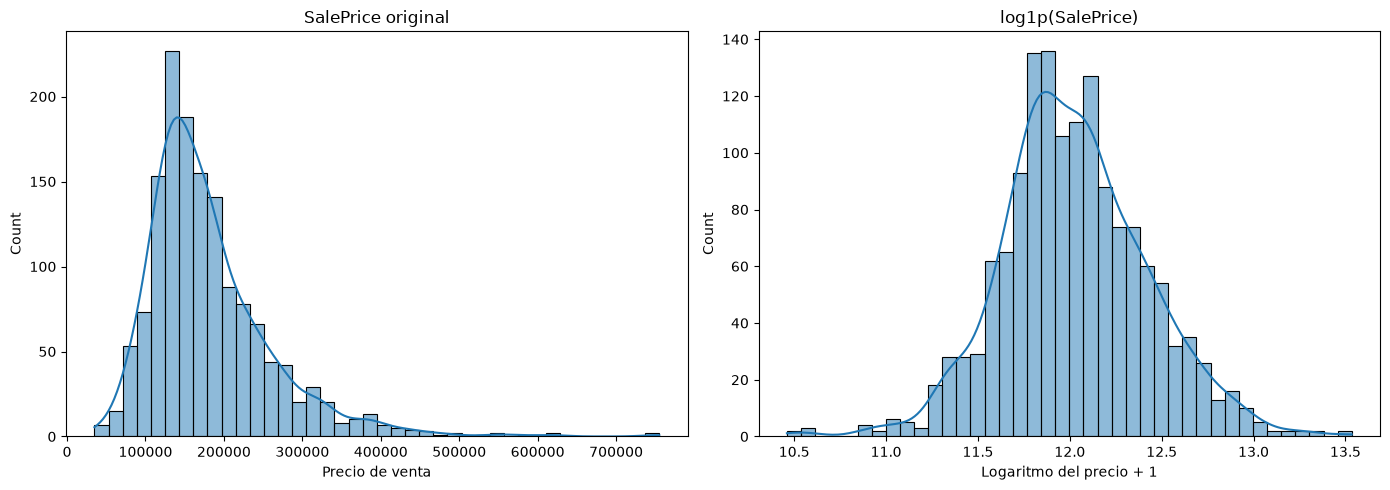

Asimetría original: 1.8828757597682129
Asimetría logarítmica: 0.12134661989685333


In [ ]:
# Transformación logarítmica para estudiar la distribución.
saleprice_log = np.log1p(train["SalePrice"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    train["SalePrice"],
    bins=40,
    kde=True,
    ax=axes[0],
)

axes[0].set_title("SalePrice original")
axes[0].set_xlabel("Precio de venta")

sns.histplot(
    saleprice_log,
    bins=40,
    kde=True,
    ax=axes[1],
)

axes[1].set_title("log1p(SalePrice)")
axes[1].set_xlabel("Logaritmo del precio + 1")

plt.tight_layout()
plt.show()

print(
    "Asimetría original:",
    train["SalePrice"].skew()
)

print(
    "Asimetría logarítmica:",
    saleprice_log.skew()
)

In [16]:
# Calcular los cuartiles y el rango intercuartílico.
q1 = train["SalePrice"].quantile(0.25)
q3 = train["SalePrice"].quantile(0.75)

iqr = q3 - q1

# Límites para señalar posibles valores atípicos.
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print(f"Q1: {q1:,.0f} $")
print(f"Q3: {q3:,.0f} $")
print(f"IQR: {iqr:,.0f} $")
print(f"Límite inferior: {lower_bound:,.0f} $")
print(f"Límite superior: {upper_bound:,.0f} $")

# Identificar los precios que quedan fuera de los límites.
outlier_mask = (
    (train["SalePrice"] < lower_bound)
    | (train["SalePrice"] > upper_bound)
)

print("\nNúmero de posibles valores atípicos:", outlier_mask.sum())

# Inspeccionar las viviendas más caras.
display(
    train.loc[
        train["SalePrice"] > upper_bound,
        ["Id", "SalePrice"]
    ].sort_values("SalePrice", ascending=False).head(10)
)

Q1: 129,975 $
Q3: 214,000 $
IQR: 84,025 $
Límite inferior: 3,938 $
Límite superior: 340,038 $

Número de posibles valores atípicos: 61


,Id,SalePrice
691,692,755000
1182,1183,745000
1169,1170,625000
898,899,611657
803,804,582933
1046,1047,556581
440,441,555000
769,770,538000
178,179,501837
798,799,485000


In [17]:
# Separar las viviendas señaladas por el IQR y el resto.
price_outliers = train.loc[
    train["SalePrice"] > upper_bound
].copy()

regular_prices = train.loc[
    train["SalePrice"] <= upper_bound
].copy()

# Inspeccionar las 15 viviendas con el precio más alto.
columns = [
    "Id",
    "SalePrice",
    "OverallQual",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageArea",
    "YearBuilt",
    "Neighborhood",
]

display(
    price_outliers[columns]
    .sort_values("SalePrice", ascending=False)
    .head(15)
)

# Comparar las características de ambos grupos.
features_to_compare = [
    "OverallQual",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageArea",
    "YearBuilt",
    "LotArea",
]

comparison = pd.DataFrame({
    "Viviendas señaladas": price_outliers[
        features_to_compare
    ].median(),
    "Resto de viviendas": regular_prices[
        features_to_compare
    ].median(),
})

display(comparison)

print(
    "Porcentaje de viviendas señaladas:",
    round(len(price_outliers) / len(train) * 100, 2),
    "%"
)

,Id,SalePrice,OverallQual,GrLivArea,TotalBsmtSF,GarageArea,YearBuilt,Neighborhood
691,692,755000,10,4316,2444,832,1994,NoRidge
1182,1183,745000,10,4476,2396,813,1996,NoRidge
1169,1170,625000,10,3627,1930,807,1995,NoRidge
898,899,611657,9,2364,2330,820,2009,NridgHt
803,804,582933,9,2822,1734,1020,2008,NridgHt
1046,1047,556581,9,2868,1992,716,2005,StoneBr
440,441,555000,10,2402,3094,672,2008,NridgHt
769,770,538000,8,3279,1650,841,2003,StoneBr
178,179,501837,9,2234,2216,1166,2008,StoneBr
798,799,485000,9,3140,1926,820,2008,NridgHt


,Viviendas señaladas,Resto de viviendas
OverallQual,9.0,6.0
GrLivArea,2364.0,1437.0
TotalBsmtSF,1856.0,973.0
GarageArea,820.0,471.0
YearBuilt,2006.0,1971.0
LotArea,13682.0,9317.0


Porcentaje de viviendas señaladas: 4.18 %


### Conclusión: valores atípicos de SalePrice

La regla del rango intercuartílico (IQR) ha identificado 61 viviendas
con precios superiores a 340.038 $, aproximadamente el 4,18 % del
conjunto de entrenamiento.

La inspección de sus características indica que las viviendas más
caras tienden a tener superficies y características superiores a las
del resto del conjunto.

**Decisión:** conservar estas observaciones. Superar el límite del IQR
no implica que un dato sea incorrecto. No eliminaremos viviendas
únicamente por tener precios elevados.

Revisaremos posteriormente las relaciones entre superficie y precio
para detectar posibles inconsistencias y evaluaremos cualquier
tratamiento adicional mediante validación del modelo.

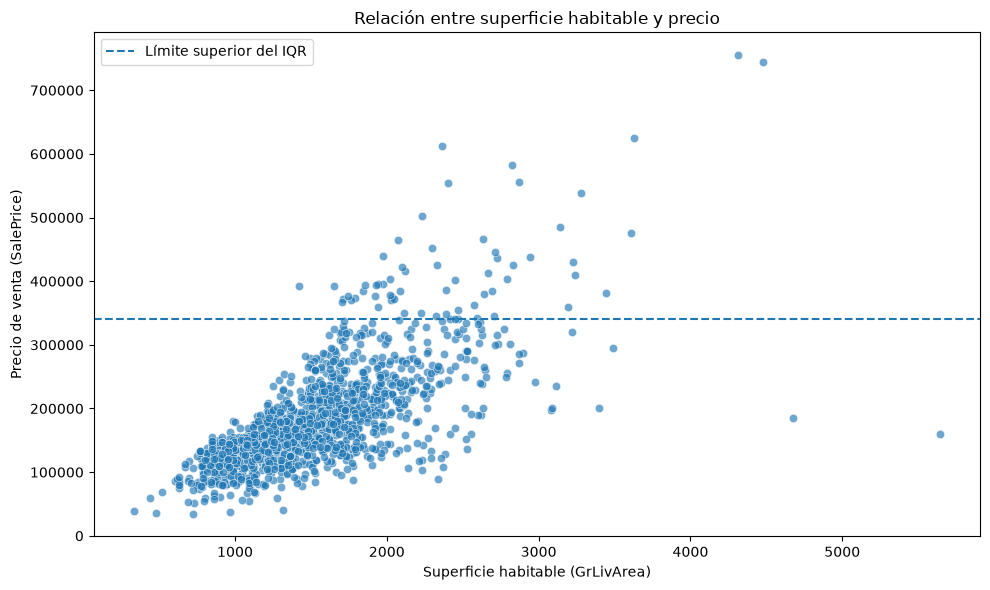

In [18]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=train,
    x="GrLivArea",
    y="SalePrice",
    alpha=0.65,
)

plt.axhline(
    upper_bound,
    linestyle="--",
    label="Límite superior del IQR",
)

plt.title("Relación entre superficie habitable y precio")
plt.xlabel("Superficie habitable (GrLivArea)")
plt.ylabel("Precio de venta (SalePrice)")
plt.legend()
plt.tight_layout()
plt.show()

### Relación entre superficie habitable y precio

El diagrama de dispersión de `GrLivArea` frente a `SalePrice` muestra
una tendencia positiva: generalmente, las viviendas con mayor
superficie habitable tienen precios más elevados.

Sin embargo, existe una dispersión considerable. Viviendas con
superficies diferentes pueden presentar precios similares, y viviendas
con superficies parecidas pueden venderse a precios muy distintos.

**Conclusión:** `GrLivArea` parece ser una característica predictiva
relevante, pero no explica por sí sola el precio. Investigaremos otras
variables, como la calidad general, el barrio y la antigüedad, para
comprender mejor estas diferencias.

Por ahora, no eliminaremos observaciones basándonos únicamente en
su superficie o precio.

In [19]:
# Resumir el precio según la calidad general.
quality_summary = (
    train.groupby("OverallQual")["SalePrice"]
    .agg(
        count="count",
        median_price="median",
        mean_price="mean",
    )
    .round(2)
)

display(quality_summary)

,count,median_price,mean_price
OverallQual,,,
1,2,50150.0,50150.00
2,3,60000.0,51770.33
3,20,86250.0,87473.75
4,116,108000.0,108420.66
5,397,133000.0,133523.35
6,374,160000.0,161603.03
7,319,200141.0,207716.42
8,168,269750.0,274735.54
9,43,345000.0,367513.02


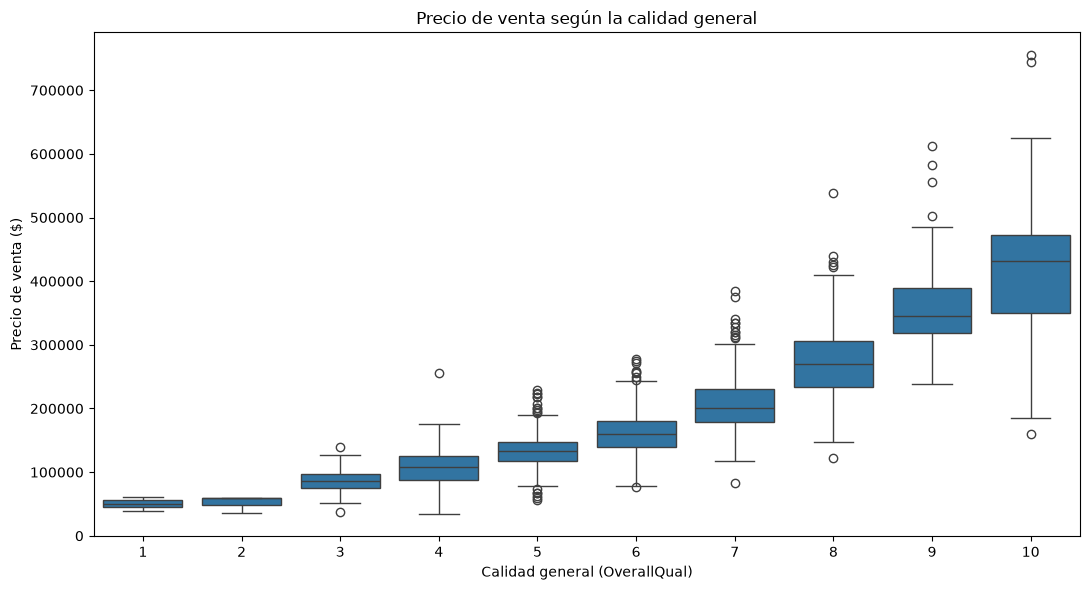

In [20]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=train,
    x="OverallQual",
    y="SalePrice",
)

plt.title("Precio de venta según la calidad general")
plt.xlabel("Calidad general (OverallQual)")
plt.ylabel("Precio de venta ($)")

plt.tight_layout()
plt.show()

### Relación entre calidad general y precio

El análisis de `OverallQual` muestra que, en general, los precios
medios de venta aumentan a medida que aumenta la calidad de la vivienda.

Esta relación complementa la observada entre superficie habitable
(`GrLivArea`) y precio (`SalePrice`).

**Conclusión:** la calidad general parece ser una característica
predictiva relevante. Sin embargo, la relación no implica causalidad
y debemos considerar la dispersión de los precios dentro de cada nivel
de calidad, así como el número de viviendas de cada grupo.

Conservaremos esta variable para la posterior comparación de modelos.

In [21]:
# Resumir los precios por barrio.
neighborhood_summary = (
    train.groupby("Neighborhood")["SalePrice"]
    .agg(
        count="count",
        median_price="median",
        mean_price="mean",
    )
    .sort_values("median_price")
    .round(2)
)

display(neighborhood_summary)

,count,median_price,mean_price
Neighborhood,,,
MeadowV,17,88000.0,98576.47
IDOTRR,37,103000.0,100123.78
BrDale,16,106000.0,104493.75
OldTown,113,119000.0,128225.30
Edwards,100,121750.0,128219.70
BrkSide,58,124300.0,124834.05
Sawyer,74,135000.0,136793.14
Blueste,2,137500.0,137500.00
SWISU,25,139500.0,142591.36


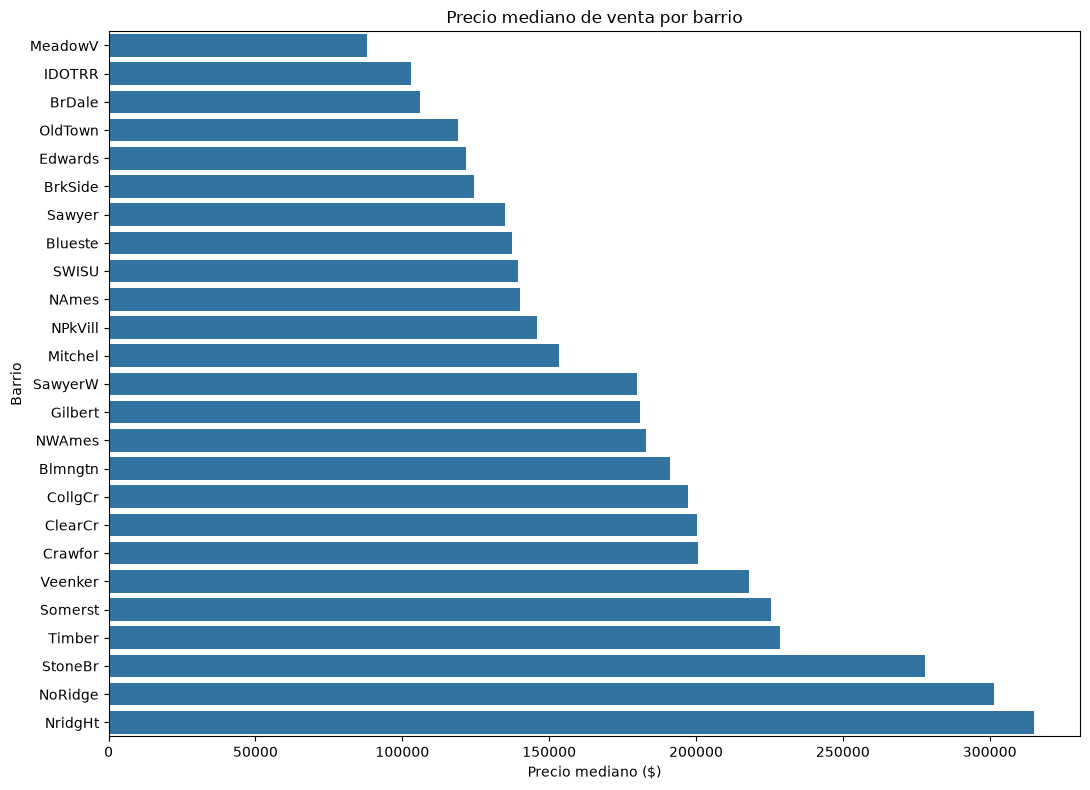

In [22]:
plt.figure(figsize=(11, 8))

sns.barplot(
    data=neighborhood_summary.reset_index(),
    x="median_price",
    y="Neighborhood",
)

plt.title("Precio mediano de venta por barrio")
plt.xlabel("Precio mediano ($)")
plt.ylabel("Barrio")

plt.tight_layout()
plt.show()

### Relación entre barrio y precio de venta

El análisis de `Neighborhood` muestra diferencias importantes en el
precio mediano de las viviendas según el barrio.

En el conjunto de entrenamiento, las medianas van desde 88.000$
en MeadowV hasta 315.000$ en NridgHt. Esto sugiere que la ubicación
contiene información potencialmente útil para predecir el precio.

El número de observaciones por barrio es desigual. Algunas categorías,
como Blueste, cuentan con muy pocas viviendas, por lo que sus
estadísticas deben interpretarse con cautela.

La media y la mediana también difieren en algunos barrios, lo que
sugiere que los precios extremos influyen en la distribución.

**Conclusión:** conservaremos `Neighborhood` como candidata a
característica predictiva y estudiaremos su tratamiento como variable
categórica. Estas asociaciones no demuestran causalidad, y tendremos
que comprobar su utilidad mediante validación del modelo.

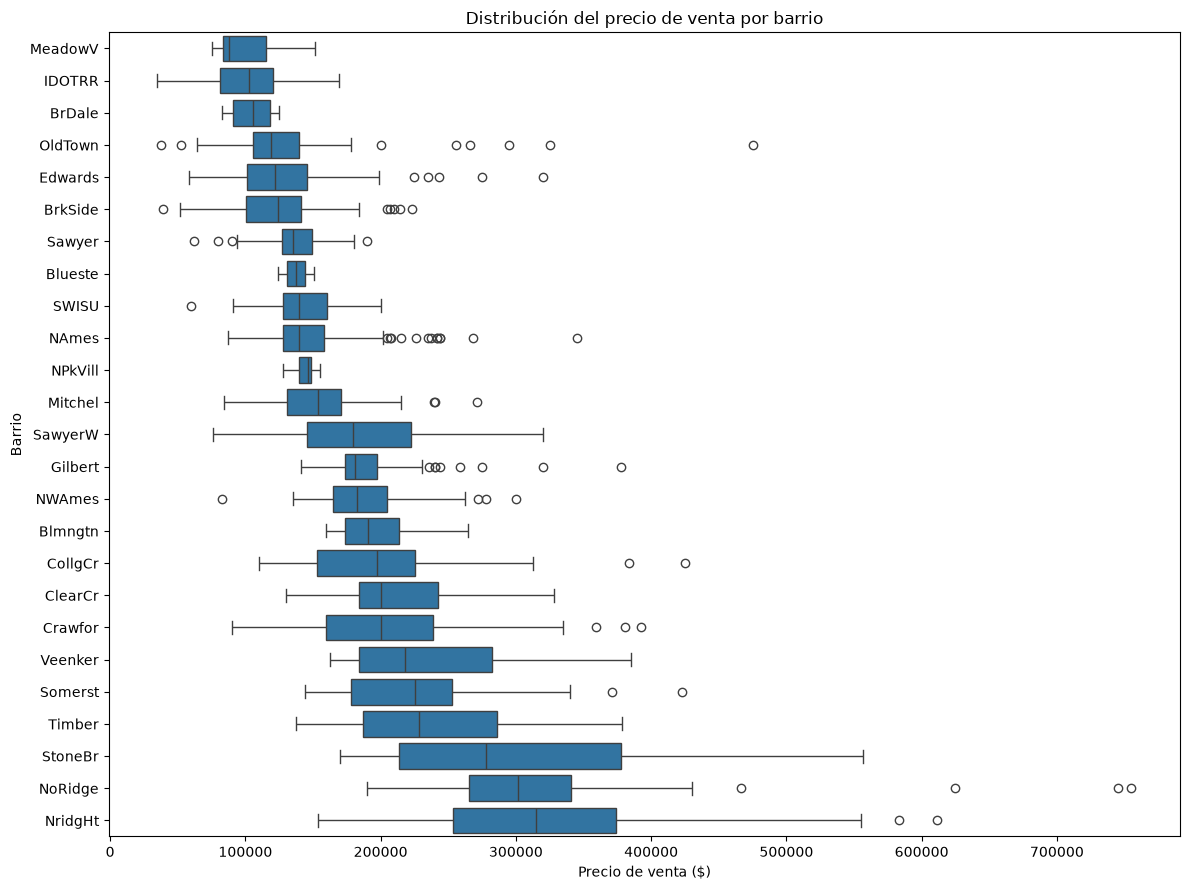

In [23]:
# Ordenar los barrios por precio mediano.
neighborhood_order = neighborhood_summary.index.tolist()

plt.figure(figsize=(12, 9))

sns.boxplot(
    data=train,
    x="SalePrice",
    y="Neighborhood",
    order=neighborhood_order,
)

plt.title("Distribución del precio de venta por barrio")
plt.xlabel("Precio de venta ($)")
plt.ylabel("Barrio")

plt.tight_layout()
plt.show()

### Correlaciones entre variables numéricas y SalePrice

In [24]:
# Seleccionar variables almacenadas como numéricas.
numeric_features = train.select_dtypes(
    include=np.number
).columns

# Excluir variables que no debemos interpretar directamente
# como cantidades continuas.
numeric_features = numeric_features.drop(
    ["Id", "MSSubClass", "MoSold", "SalePrice", "SalePrice_log"],
    errors="ignore",
)

# Calcular correlaciones con el precio de venta.
pearson_corr = train[numeric_features].corrwith(
    train["SalePrice"],
    method="pearson",
)

spearman_corr = train[numeric_features].corrwith(
    train["SalePrice"],
    method="spearman",
)

# Crear una tabla comparativa.
correlation_summary = pd.DataFrame({
    "pearson": pearson_corr,
    "spearman": spearman_corr,
})

# Ordenar por la fuerza de la asociación más alta
# entre ambas métricas.
correlation_summary["max_abs_corr"] = (
    correlation_summary[["pearson", "spearman"]]
    .abs()
    .max(axis=1)
)

correlation_summary = correlation_summary.sort_values(
    "max_abs_corr",
    ascending=False,
)

display(correlation_summary.drop(columns="max_abs_corr"))

,pearson,spearman
OverallQual,0.790982,0.809829
GrLivArea,0.708624,0.731310
GarageCars,0.640409,0.690711
YearBuilt,0.522897,0.652682
GarageArea,0.623431,0.649379
FullBath,0.560664,0.635957
TotalBsmtSF,0.613581,0.602725
1stFlrSF,0.605852,0.575408
GarageYrBlt,0.486362,0.593788
YearRemodAdd,0.507101,0.571159


### Correlación entre variables predictoras

In [25]:
# Usamos las características numéricas que seleccionamos antes.
X_numeric = train[numeric_features]

# Matriz de correlación de Spearman entre predictoras.
corr_features = X_numeric.corr(method="spearman")

# Seleccionar solamente una mitad de la matriz
# para evitar parejas duplicadas.
upper_triangle = corr_features.where(
    np.triu(
        np.ones(corr_features.shape, dtype=bool),
        k=1
    )
)

# Convertir la matriz en una tabla de parejas.
correlation_pairs = (
    upper_triangle
    .stack()
    .rename("spearman_corr")
    .reset_index()
)

correlation_pairs.columns = [
    "feature_1",
    "feature_2",
    "spearman_corr",
]

# Ordenar por la fuerza de la asociación.
correlation_pairs["abs_corr"] = (
    correlation_pairs["spearman_corr"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    "abs_corr",
    ascending=False,
)

# Mostrar las parejas con una asociación fuerte.
strong_pairs = correlation_pairs.loc[
    correlation_pairs["abs_corr"] >= 0.75
].drop(columns="abs_corr")

display(strong_pairs)

,feature_1,feature_2,spearman_corr
159,YearBuilt,GarageYrBlt,0.890546
841,GarageCars,GarageArea,0.853317
351,TotalBsmtSF,1stFlrSF,0.829292
497,GrLivArea,TotRmsAbvGrd,0.827874


### Correlación entre variables predictoras

El análisis de Spearman ha identificado cuatro parejas de variables
con una correlación absoluta superior a 0,75:

- `YearBuilt` y `GarageYrBlt`: 0,891.
- `GarageCars` y `GarageArea`: 0,853.
- `TotalBsmtSF` y `1stFlrSF`: 0,829.
- `GrLivArea` y `TotRmsAbvGrd`: 0,828.

Estas relaciones son coherentes con el significado de las
características: las viviendas más recientes tienden a tener garajes
más recientes, y las viviendas más grandes suelen tener más habitaciones
o superficies mayores en otras partes del inmueble.

**Decisión:** conservar inicialmente todas estas variables. La
correlación entre predictoras no implica que sean intercambiables ni
que una de ellas sea necesariamente prescindible. Evaluaremos su
aportación dentro de los modelos y tendremos en cuenta sus posibles
efectos sobre la estabilidad y la interpretación.

### Análisis global de variables categóricas

In [26]:
# Identificar columnas almacenadas como texto o categorías.
categorical_cols = [
    col
    for col in train.columns
    if str(train[col].dtype)
    in {"str", "object", "string", "category"}
]

# No incluir la variable objetivo.
categorical_cols = [
    col for col in categorical_cols
    if col != "SalePrice"
]

# Resumir la estructura de cada variable.
categorical_summary = pd.DataFrame({
    "unique_values": {
        col: train[col].nunique(dropna=True)
        for col in categorical_cols
    },
    "missing_count": {
        col: train[col].isna().sum()
        for col in categorical_cols
    },
    "missing_pct": {
        col: train[col].isna().mean() * 100
        for col in categorical_cols
    },
})

categorical_summary["missing_pct"] = (
    categorical_summary["missing_pct"].round(2)
)

categorical_summary = categorical_summary.sort_values(
    ["unique_values", "missing_pct"],
    ascending=[False, False],
)

display(categorical_summary)

,unique_values,missing_count,missing_pct
Neighborhood,25,0,0.00
Exterior2nd,16,0,0.00
Exterior1st,15,0,0.00
Condition1,9,0,0.00
SaleType,9,0,0.00
Condition2,8,0,0.00
HouseStyle,8,0,0.00
RoofMatl,8,0,0.00
Functional,7,0,0.00
GarageType,6,81,5.55


### Relación entre calidad categórica y precio

In [27]:
# Variables categóricas de calidad que vamos a investigar.
quality_features = [
    "ExterQual",
    "KitchenQual",
    "HeatingQC",
    "BsmtQual",
]

# Orden de las categorías de calidad.
quality_order = ["Po", "Fa", "TA", "Gd", "Ex"]

for col in quality_features:

    # Crear una copia para el análisis.
    # No modificamos el DataFrame original.
    analysis_data = train[[col, "SalePrice"]].copy()

    # En BsmtQual, la ausencia representa que no hay sótano.
    if col == "BsmtQual":
        analysis_data[col] = (
            analysis_data[col].fillna("NoBasement")
        )
    else:
        analysis_data[col] = (
            analysis_data[col].fillna("Missing")
        )

    # Comparar precios por categoría.
    summary = (
        analysis_data.groupby(col)["SalePrice"]
        .agg(
            count="count",
            median_price="median",
            mean_price="mean",
        )
    )

    # Ordenar por el nivel de calidad.
    if col == "BsmtQual":
        ordered_categories = [
            "NoBasement",
            *quality_order,
        ]
    else:
        ordered_categories = [
            *quality_order,
            "Missing",
        ]

    ordered_categories += [
        category
        for category in summary.index
        if category not in ordered_categories
    ]

    summary = summary.reindex(
        [category for category in ordered_categories
         if category in summary.index]
    )

    print(f"\n=== {col} ===")
    display(summary.round(2))


=== ExterQual ===


,count,median_price,mean_price
ExterQual,,,
Fa,14,82250.0,87985.21
TA,906,139450.0,144341.31
Gd,488,220000.0,231633.51
Ex,52,364606.5,367360.96



=== KitchenQual ===


,count,median_price,mean_price
KitchenQual,,,
Fa,39,115000.0,105565.21
TA,735,137000.0,139962.51
Gd,586,201400.0,212116.02
Ex,100,316750.0,328554.67



=== HeatingQC ===


,count,median_price,mean_price
HeatingQC,,,
Po,1,87000.0,87000.00
Fa,49,123500.0,123919.49
TA,428,135000.0,142362.88
Gd,241,152000.0,156858.87
Ex,741,194700.0,214914.43



=== BsmtQual ===


,count,median_price,mean_price
BsmtQual,,,
NoBasement,37,101800.0,105652.89
Fa,35,112000.0,115692.03
TA,649,135500.0,140759.82
Gd,618,192070.0,202688.48
Ex,121,318000.0,327041.04


### Conclusión: variables categóricas de calidad

Los precios medianos tienden a aumentar con los niveles de calidad de
las variables `ExterQual`, `KitchenQual`, `HeatingQC` y `BsmtQual`.

Esto sugiere que las características ordinales de calidad contienen
información útil para predecir el precio.

La categoría `Po` de `HeatingQC` cuenta con una única observación,
por lo que su estadística no es representativa de un grupo amplio.
No eliminaremos ni fusionaremos categorías automáticamente: evaluaremos
su tratamiento durante el preprocesamiento y el modelado.

In [28]:
categorical_features_to_explore = [
    "MSZoning",
    "BldgType",
    "HouseStyle",
    "Foundation",
    "CentralAir",
    "SaleCondition",
    "GarageType",
]

for col in categorical_features_to_explore:
    # Crear una serie auxiliar sin modificar los datos originales.
    categories = train[col].astype("object").copy()

    # En GarageType, la ausencia significa que no hay garaje.
    if col == "GarageType":
        categories = categories.fillna("NoGarage")
    else:
        categories = categories.fillna("Missing")

    analysis_data = pd.DataFrame({
        "category": categories,
        "SalePrice": train["SalePrice"],
    })

    summary = (
        analysis_data.groupby("category")["SalePrice"]
        .agg(
            count="count",
            median_price="median",
            mean_price="mean",
        )
        .sort_values("median_price")
        .round(2)
    )

    print(f"\n=== {col} ===")
    display(summary)


=== MSZoning ===


,count,median_price,mean_price
category,,,
C (all),10,74700.0,74528.00
RM,218,120500.0,126316.83
RH,16,136500.0,131558.38
RL,1151,174000.0,191004.99
FV,65,205950.0,214014.06



=== BldgType ===


,count,median_price,mean_price
category,,,
2fmCon,31,127500.0,128432.26
Duplex,52,135980.0,133541.08
Twnhs,43,137500.0,135911.63
1Fam,1220,167900.0,185763.81
TwnhsE,114,172200.0,181959.34



=== HouseStyle ===


...

,count,median_price,mean_price
category,,,
N,95,98000.0,105264.07
Y,1365,168000.0,186186.71



=== SaleCondition ===


,count,median_price,mean_price
category,,,
AdjLand,4,104000.0,104125.00
Abnorml,101,130000.0,146526.62
Family,20,140500.0,149600.00
Alloca,12,148145.0,167377.42
Normal,1198,160000.0,175202.22
Partial,125,244600.0,272291.75



=== GarageType ===


,count,median_price,mean_price
category,,,
NoGarage,81,100000.0,103317.28
CarPort,9,108000.0,109962.11
Detchd,387,129500.0,134091.16
Basment,19,148000.0,160570.68
2Types,6,159000.0,151283.33
Attchd,870,185000.0,202892.66
BuiltIn,88,227500.0,254751.74


### Conclusión: variables categóricas nominales

El análisis de variables como `MSZoning`, `BldgType`, `HouseStyle`,
`Foundation`, `CentralAir`, `SaleCondition` y `GarageType` muestra
diferencias entre los precios medianos de sus categorías.

Estas asociaciones sugieren que las variables categóricas contienen
información potencialmente útil para predecir `SalePrice`.

Algunas categorías tienen pocas observaciones, por lo que sus
estadísticas deben interpretarse con cautela.

**Decisión:** conservar estas variables como candidatas para los
modelos. Durante el preprocesamiento se distinguirán las variables
nominales de las ordinales y se evaluará una codificación adecuada.
No eliminaremos ni agruparemos categorías únicamente por tener
pocas observaciones.

In [29]:
# Variables que representan cantidades continuas.
continuous_features = [
    "LotFrontage",
    "LotArea",
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "LowQualFinSF",
    "GrLivArea",
    "GarageArea",
    "WoodDeckSF",
    "OpenPorchSF",
    "EnclosedPorch",
    "3SsnPorch",
    "ScreenPorch",
    "PoolArea",
    "MiscVal",
]

# Calcular únicamente las columnas disponibles.
continuous_features = [
    col for col in continuous_features
    if col in train.columns
]

# Crear un resumen de distribución.
distribution_summary = pd.DataFrame(index=continuous_features)

distribution_summary["skewness"] = (
    train[continuous_features].skew()
)

distribution_summary["zero_pct"] = (
    train[continuous_features].eq(0).mean() * 100
)

distribution_summary["missing_pct"] = (
    train[continuous_features].isna().mean() * 100
)

distribution_summary["unique_values"] = (
    train[continuous_features].nunique()
)

distribution_summary["abs_skewness"] = (
    distribution_summary["skewness"].abs()
)

# Ordenar por asimetría absoluta.
distribution_summary = distribution_summary.sort_values(
    "abs_skewness",
    ascending=False,
)

display(
    distribution_summary
    .drop(columns="abs_skewness")
    .round(2)
)

,skewness,zero_pct,missing_pct,unique_values
MiscVal,24.48,96.44,0.00,21
PoolArea,14.83,99.52,0.00,8
LotArea,12.21,0.00,0.00,1073
3SsnPorch,10.30,98.36,0.00,20
LowQualFinSF,9.01,98.22,0.00,24
BsmtFinSF2,4.26,88.56,0.00,144
ScreenPorch,4.12,92.05,0.00,76
EnclosedPorch,3.09,85.75,0.00,120
MasVnrArea,2.67,58.97,0.55,327
OpenPorchSF,2.36,44.93,0.00,202


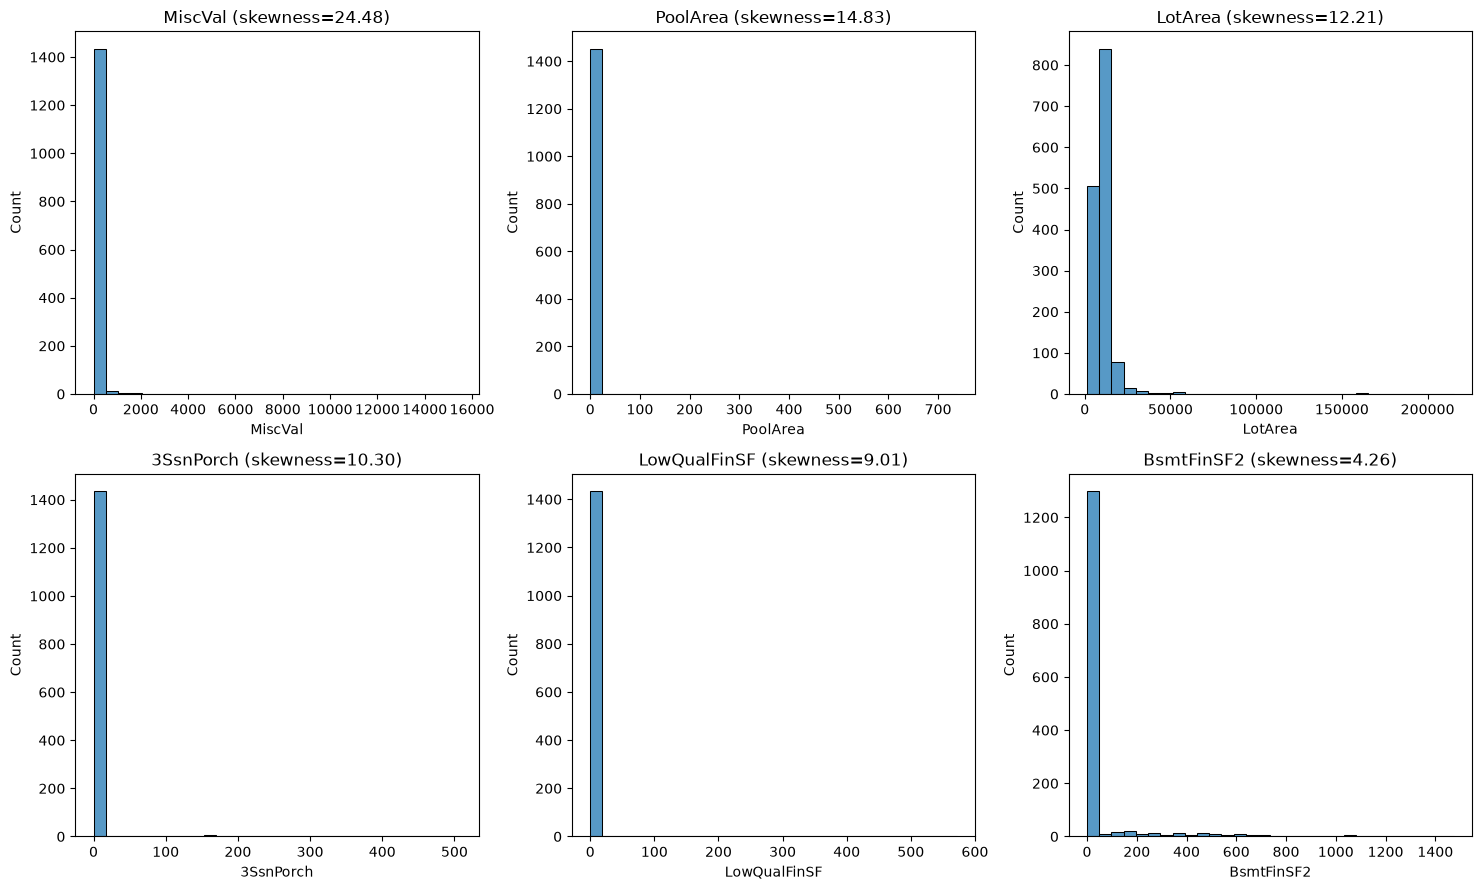

In [30]:
# Seleccionar las seis variables con mayor asimetría absoluta.
top_skewed = distribution_summary.head(6).index

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, col in zip(axes.flat, top_skewed):
    sns.histplot(
        data=train,
        x=col,
        bins=30,
        ax=ax,
    )

    ax.set_title(
        f"{col} (skewness="
        f"{distribution_summary.loc[col, 'skewness']:.2f})"
    )

plt.tight_layout()
plt.show()

### Conclusión: distribución de las variables numéricas

Varias características presentan distribuciones asimétricas, especialmente `LotArea`, `MiscVal` y `PoolArea`. Algunas variables relacionadas con características poco frecuentes de las viviendas contienen una proporción muy elevada de ceros.

**Decisión:** conservar las variables originales por ahora. Durante la comparación de modelos evaluaremos si las transformaciones logarítmicas o la creación de indicadores de presencia mejoran el rendimiento. No aplicaremos transformaciones únicamente para reducir la asimetría.